# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [3]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

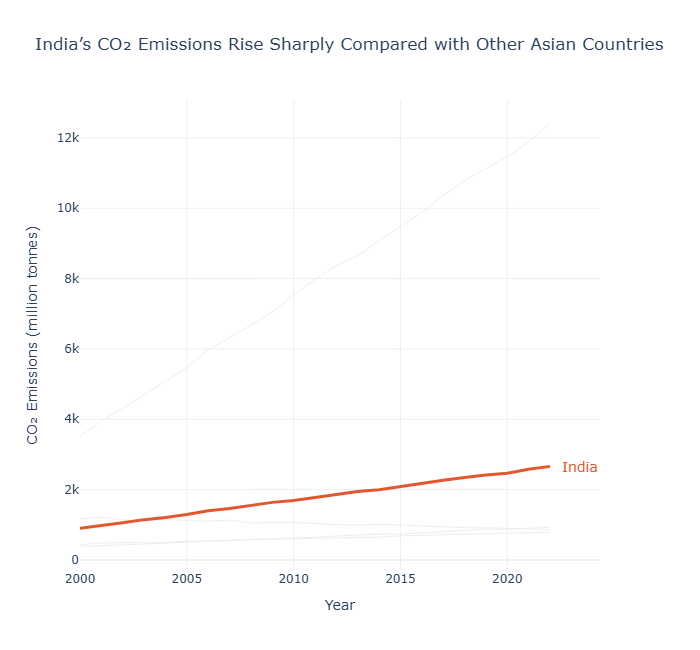

In [6]:
# Task — Multi-Series Line Chart with Highlight
# ----------------------------------------------

import pandas as pd
import plotly.graph_objects as go

# Step 1: Filter all Asian countries
asia = df[df['Region'] == 'Asia'].copy()

# Step 2: Choose the country to highlight
highlight_country = 'India'

# Step 3: Create the chart
fig = go.Figure()

# Add all other Asian countries in light grey
for country in asia['Country'].unique():

    if country == highlight_country:
        continue

    country_data = (
        asia[asia['Country'] == country]
        .sort_values('Year')
    )

    fig.add_trace(go.Scatter(
        x=country_data['Year'],
        y=country_data['CO2_Mt'],
        mode='lines',
        line=dict(
            color='#EEEEEE',
            width=1
        ),
        name=country,
        showlegend=False,
        hovertemplate=(
            f'{country}<br>'
            'Year: %{x}<br>'
            'CO₂ emissions: %{y:.1f} Mt'
            '<extra></extra>'
        )
    ))

# Step 4: Add India as the highlighted country
highlight_data = (
    asia[asia['Country'] == highlight_country]
    .sort_values('Year')
)

if highlight_data.empty:
    raise ValueError(
        f'{highlight_country} was not found in the Asian data. '
        f'Available countries: {asia["Country"].unique().tolist()}'
    )

fig.add_trace(go.Scatter(
    x=highlight_data['Year'],
    y=highlight_data['CO2_Mt'],
    mode='lines',
    line=dict(
        color='#E4572E',
        width=3
    ),
    name=highlight_country,
    showlegend=False,
    hovertemplate=(
        'India<br>'
        'Year: %{x}<br>'
        'CO₂ emissions: %{y:.1f} Mt'
        '<extra></extra>'
    )
))

# Step 5: Label India directly at the end of its line
last_point = highlight_data.iloc[-1]

fig.add_annotation(
    x=last_point['Year'],
    y=last_point['CO2_Mt'],
    text='India',
    showarrow=False,
    xshift=30,
    font=dict(
        color='#E4572E',
        size=14
    )
)

# Step 6: Add title and improve layout
fig.update_layout(
    title=(
        'India’s CO₂ Emissions Rise Sharply Compared '
        'with Other Asian Countries'
    ),
    xaxis_title='Year',
    yaxis_title='CO₂ Emissions (million tonnes)',
    template='plotly_white',
    hovermode='x unified',
    height=650,
    margin=dict(r=100),
    showlegend=False
)

# Step 7: Display the chart
fig.show(renderer="png")